In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

In [31]:
df = pd.read_csv('C:\\Users\\DELL\\Desktop\\ml\\task1\\data.csv')
print(f"Dataset Dimensrions : Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("---------Dataset Info---------")
print(df.info())

print("---------Dataset Describe---------")
print(df.describe())

print('---------Target Variable Distribution---------')
print(df['Churn'].value_counts())

Dataset Dimensrions : Rows: 7043, Columns: 21
---------Dataset Info---------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract    

In [32]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}") 

df.drop_duplicates(inplace=True)
print(f"duplicated rows removed, new dataset dimensrions : Rows: {df.shape[0]}, Columns: {df.shape[1]}")

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce') 

print("---------Missing Values---------")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

df['TotalCharges'] = df['TotalCharges'].fillna(df['tenure']*df['MonthlyCharges'])
print(f"\nRemaining Missing Values in TotalCharges: {df['TotalCharges'].isnull().sum()}")

df_clean = df.drop(columns=['customerID'])

print("--- Summary of Cleaned Data ---")
print(f"Cleaned Dataset Shape: {df_clean.shape}")
print("Updated Column Data Types:")
print(df_clean.dtypes[['tenure', 'MonthlyCharges', 'TotalCharges']])

Number of duplicate rows: 0
duplicated rows removed, new dataset dimensrions : Rows: 7043, Columns: 21
---------Missing Values---------
TotalCharges    11
dtype: int64

Remaining Missing Values in TotalCharges: 0
--- Summary of Cleaned Data ---
Cleaned Dataset Shape: (7043, 20)
Updated Column Data Types:
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


C:\Users\DELL\AppData\Local\Temp\ipykernel_31124\239770894.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Churn', ax=axes[0, 0], palette='Set2')
C:\Users\DELL\AppData\Local\Temp\ipykernel_31124\239770894.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Churn', y='tenure', ax=axes[1, 0], palette='Set2')


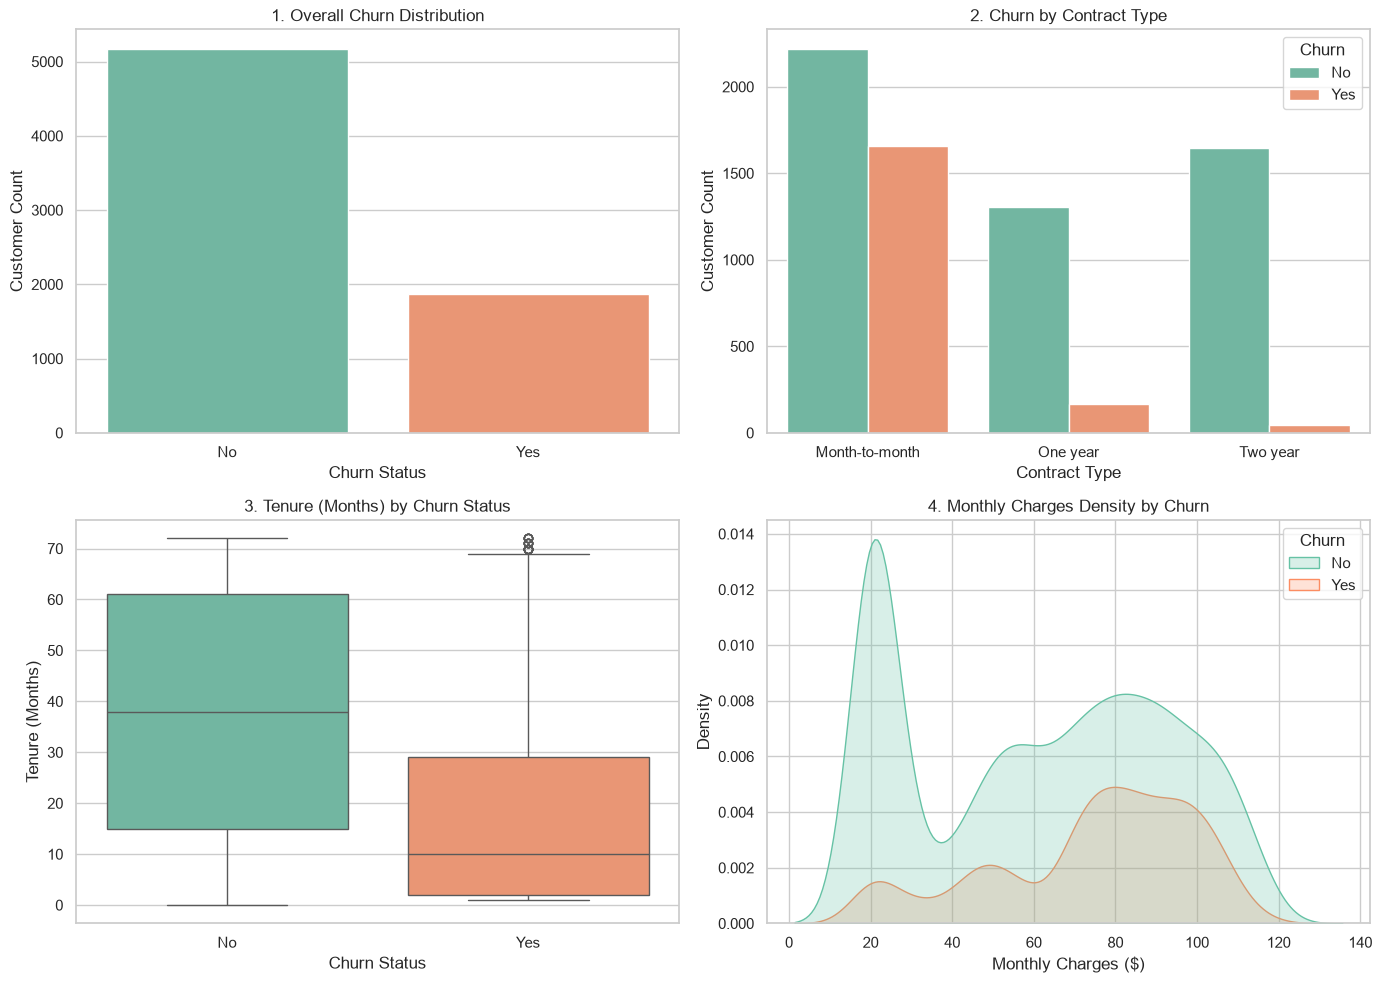

--- Churn Rate by Contract Type (%) ---


Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


--- Churn Rate by Internet Service (%) ---


Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980



--- Average Numerical Values by Churn ---


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


In [29]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_clean, x='Churn', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('1. Overall Churn Distribution')
axes[0, 0].set_xlabel('Churn Status')
axes[0, 0].set_ylabel('Customer Count')

sns.countplot(data=df_clean, x='Contract', hue='Churn', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('2. Churn by Contract Type')
axes[0, 1].set_xlabel('Contract Type')
axes[0, 1].set_ylabel('Customer Count')

sns.boxplot(data=df_clean, x='Churn', y='tenure', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('3. Tenure (Months) by Churn Status')
axes[1, 0].set_xlabel('Churn Status')
axes[1, 0].set_ylabel('Tenure (Months)')

sns.kdeplot(data=df_clean, x='MonthlyCharges', hue='Churn', fill=True, ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('4. Monthly Charges Density by Churn')
axes[1, 1].set_xlabel('Monthly Charges ($)')
axes[1, 1].set_ylabel('Density')

plt.tight_layout()
plt.show()

print("--- Churn Rate by Contract Type (%) ---")
display(pd.crosstab(df_clean['Contract'], df_clean['Churn'], normalize='index') * 100)

print("--- Churn Rate by Internet Service (%) ---")
display(pd.crosstab(df_clean['InternetService'], df_clean['Churn'], normalize='index') * 100)

print("\n--- Average Numerical Values by Churn ---")
display(df_clean.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean())

In [40]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['tenure'] * df['MonthlyCharges'])
df_clean = df.drop(columns=['customerID'])

df_clean['AvgMonthlyCharge_Ratio'] = df_clean['TotalCharges'] / (df_clean['tenure'] + 1)


df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    df_clean[col] = df_clean[col].map({'Yes': 1, 'No': 0})

categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

print("--- Final Matrix Dimensions ---")
print(f"Input Features (X) shape: {X.shape}")
print(f"Target Variable (y) shape: {y.shape}")

print("\n--- Processed Feature Columns (First 10) ---")
print(X.columns.tolist()[:10])

--- Final Matrix Dimensions ---
Input Features (X) shape: (7043, 31)
Target Variable (y) shape: (7043,)

--- Processed Feature Columns (First 10) ---
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge_Ratio', 'gender_Male']


=== Classification Metrics Comparison ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8084,0.6757,0.5348,0.5970
1,Random Forest,0.7885,0.6310,0.4893,0.5512


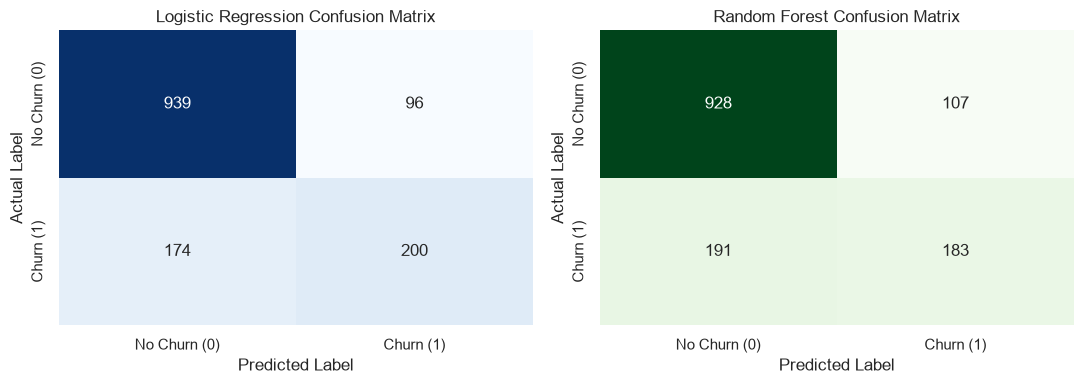

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

metrics_summary = {
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    'Precision': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    'Recall': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_rf)],
    'F1-Score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)]
}

metrics_df = pd.DataFrame(metrics_summary)
print("=== Classification Metrics Comparison ===")
display(metrics_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')
axes[0].set_xticklabels(['No Churn (0)', 'Churn (1)'])
axes[0].set_yticklabels(['No Churn (0)', 'Churn (1)'])

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')
axes[1].set_xticklabels(['No Churn (0)', 'Churn (1)'])
axes[1].set_yticklabels(['No Churn (0)', 'Churn (1)'])

plt.tight_layout()
plt.show()

In [41]:
y_pred_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

churn_sample_idx = np.where(y_pred_proba > 0.70)[0][0]     
no_churn_sample_idx = np.where(y_pred_proba < 0.20)[0][0]  

sample_customers = X_test.iloc[[churn_sample_idx, no_churn_sample_idx]]

sample_scaled = scaler.transform(sample_customers)

predictions = lr_model.predict(sample_scaled)
probabilities = lr_model.predict_proba(sample_scaled)[:, 1]

results_list = []
for i, idx in enumerate([0, 1]):
    raw_info = sample_customers.iloc[idx]
    results_list.append({
        'Customer Profile': f'Customer #{i+1}',
        'Tenure (Months)': int(raw_info['tenure']),
        'Monthly Charges ($)': raw_info['MonthlyCharges'],
        'Paperless Billing': 'Yes' if raw_info['PaperlessBilling'] == 1 else 'No',
        'Churn Risk Score (%)': f"{probabilities[idx]:.2%}",
        'Predicted Outcome': 'Churn (Yes)' if predictions[idx] == 1 else 'No Churn (No)'
    })

prediction_df = pd.DataFrame(results_list)
print("=== Real-Time Model Inference Results ===")
display(prediction_df)

=== Real-Time Model Inference Results ===


,Customer Profile,Tenure (Months),Monthly Charges ($),Paperless Billing,Churn Risk Score (%),Predicted Outcome
0,Customer #1,2,74.85,Yes,76.63%,Churn (Yes)
1,Customer #2,72,114.05,Yes,4.48%,No Churn (No)
